In [1]:
import os
DATA  = "."

for s in ["train","test","val"]:
    assert os.path.isdir(f"{DATA}/{s}"), f"'{s}' folder not found in {os.path.abspath(DATA)}"
    print(s, {c: len(os.listdir(f"{DATA}/{s}/{c}")) for c in sorted(os.listdir(f"{DATA}/{s}"))})

AssertionError: 'train' folder not found in d:\EcoSort-Ai\Machine-Learning\notebook

In [3]:
import tensorflow as tf, numpy as np
from tensorflow import keras
from tensorflow.keras import layers

ModuleNotFoundError: No module named 'tensorflow'

In [2]:
IMG = (224, 224)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE
train_ds = keras.utils.image_dataset_from_directory(f"{DATA}/train", image_size=IMG, batch_size=BATCH, shuffle=True, seed=42)
val_ds   = keras.utils.image_dataset_from_directory(f"{DATA}/val",   image_size=IMG, batch_size=BATCH, shuffle=False)
test_ds  = keras.utils.image_dataset_from_directory(f"{DATA}/test",  image_size=IMG, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(class_names)
print('GPU:', tf.config.list_physical_devices('GPU') or 'none -> training will run on CPU (slower)')

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

NameError: name 'tf' is not defined

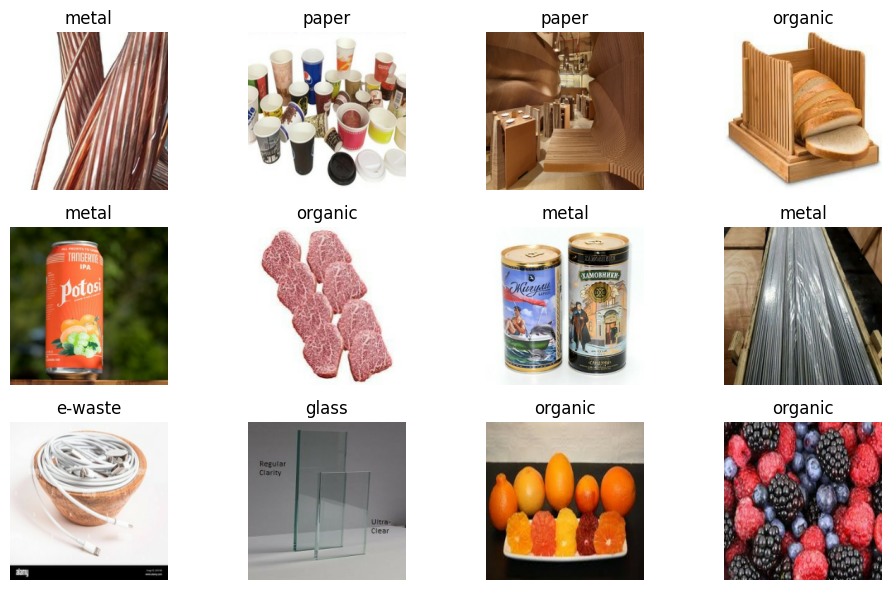

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]]); plt.axis("off")
plt.tight_layout(); plt.show()

In [6]:
counts = np.array([len(os.listdir(f"{DATA}/train/{c}")) for c in class_names])
class_weight = {i: float(counts.sum() / (NUM_CLASSES * n)) for i, n in enumerate(counts)}
print(dict(zip(class_names, counts)))
print({class_names[i]: round(w, 2) for i, w in class_weight.items()})

{'e-waste': np.int64(2124), 'glass': np.int64(1657), 'metal': np.int64(1893), 'organic': np.int64(2400), 'paper': np.int64(2400), 'plastic': np.int64(1964)}
{'e-waste': 0.98, 'glass': 1.25, 'metal': 1.1, 'organic': 0.86, 'paper': 0.86, 'plastic': 1.06}


In [7]:
from tensorflow.keras import models

In [ ]:
model  = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),    
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),


    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),


    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),                     
    layers.Dense(NUM_CLASSES, activation='softmax')   
])

In [9]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',   # labels are whole numbers 0..5
              metrics=['accuracy'])

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     5,537,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,631,494 (21.48 MB)

 Trainable params: 5,631,494 (21.48 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
EPOCHS = 20  

callbacks = [
    keras.callbacks.ModelCheckpoint("best_simple_cnn.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=callbacks)

Epoch 1/20


c:\Users\pushk\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


389/389 ━━━━━━━━━━━━━━━━━━━━ 244s 620ms/step - accuracy: 0.3279 - loss: 1.6513 - val_accuracy: 0.3509 - val_loss: 1.6043
Epoch 2/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 249s 641ms/step - accuracy: 0.3774 - loss: 1.5760 - val_accuracy: 0.4198 - val_loss: 1.4944
Epoch 3/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 267s 687ms/step - accuracy: 0.4130 - loss: 1.5073 - val_accuracy: 0.4295 - val_loss: 1.4653
Epoch 4/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 277s 712ms/step - accuracy: 0.4249 - loss: 1.4821 - val_accuracy: 0.4540 - val_loss: 1.5162
Epoch 5/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 285s 732ms/step - accuracy: 0.4492 - loss: 1.4458 - val_accuracy: 0.4868 - val_loss: 1.3773
Epoch 6/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 341s 780ms/step - accuracy: 0.4633 - loss: 1.4054 - val_accuracy: 0.4656 - val_loss: 1.4219
Epoch 7/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 272s 697ms/step - accuracy: 0.4813 - loss: 1.3736 - val_accuracy: 0.4990 - val_loss: 1.3251
Epoch 8/20
389/389 ━━━━━━━━━━━━━━━━━━━━ 241s 620ms/step - accuracy: 0.5029 - loss: 1.33

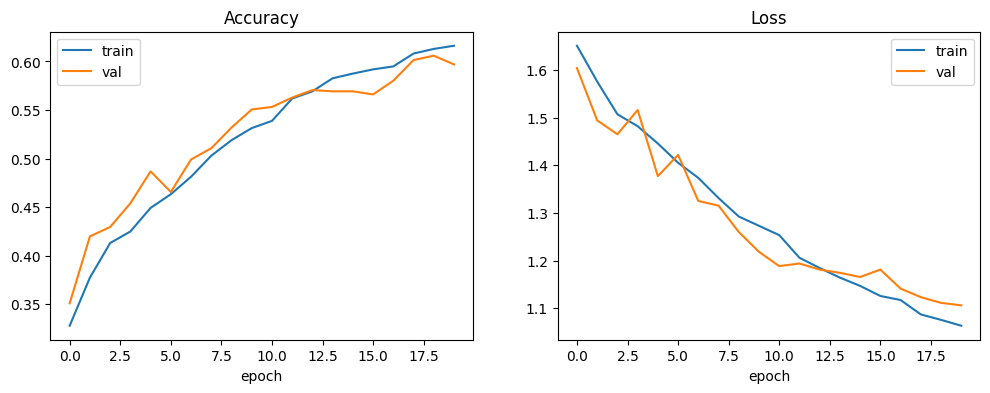

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

Test loss / accuracy: [1.0905141830444336, 0.5969191193580627]
              precision    recall  f1-score   support

     e-waste      0.601     0.639     0.619       266
       glass      0.543     0.481     0.510       208
       metal      0.582     0.445     0.505       238
     organic      0.715     0.837     0.771       300
       paper      0.518     0.583     0.549       300
     plastic      0.582     0.520     0.549       246

    accuracy                          0.597      1558
   macro avg      0.590     0.584     0.584      1558
weighted avg      0.593     0.597     0.592      1558



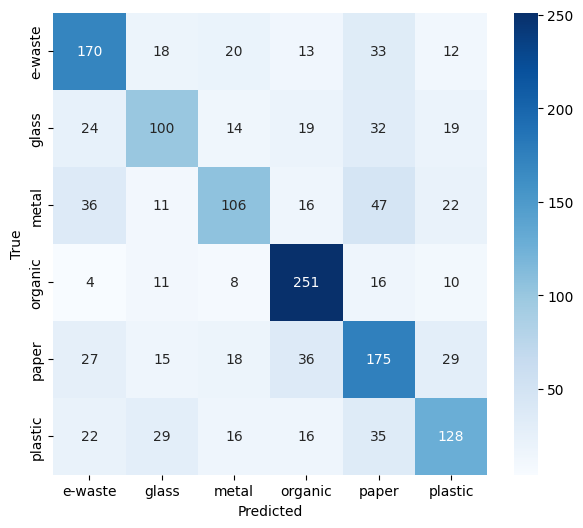

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model = keras.models.load_model("best_simple_cnn.keras")
print("Test loss / accuracy:", model.evaluate(test_ds, verbose=0))

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

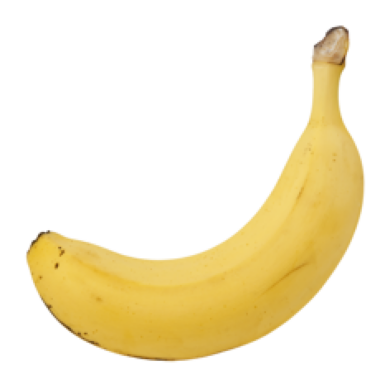

organic     45.8%
plastic     43.1%
paper        6.9%


In [15]:
from PIL import Image

def predict(path, top=3):
    img = Image.open(path).convert("RGB").resize(IMG)
    p = model.predict(np.expand_dims(np.array(img), 0), verbose=0)[0]
    plt.imshow(img); plt.axis("off"); plt.show()
    for i in np.argsort(p)[::-1][:top]:
        print(f"{class_names[i]:<10} {p[i]*100:5.1f}%")

predict("Banana-Single.jpg") 

In [16]:
import json
model.save("simple_waste_classifier.keras")
json.dump(class_names, open("class_names.json", "w"))
print("saved simple_waste_classifier.keras and class_names.json")

saved simple_waste_classifier.keras and class_names.json


In [ ]:
from PIL import Image
from pathlib import Path

model_path = Path(__file__).resolve().parent.parent/"artifact"/"simple_waste_classifier.keras"
model = keras.models.load_model(model_path)
def predict_efficient_net(path, top=3):
    img = Image.open(path).convert("RGB").resize(IMG)
    p = model.predict(np.expand_dims(np.array(img), 0), verbose=0)[0]
    plt.imshow(img); plt.axis("off"); plt.show()
    for i in np.argsort(p)[::-1][:top]:
        print(f"{class_names[i]:<10} {p[i]*100:5.1f}%")

predict("Banana-Single.jpg") 